# What drives diamond prices?

This notebook explores 308 certified diamonds and models how price depends on **carat, colour, clarity and certification**.

**Sections**
1. Setup
2. Load and check the data
3. Summary statistics
4. Exploring price and carat
5. Why raw comparisons mislead
6. Modelling price
7. Checking the model
8. Estimating the price of a new stone
9. Key findings

Keep `diamond-1.csv` in the same folder as this notebook, then choose **Run All**.

## 1. Setup

In [1]:
# If a library is missing, uncomment the next line and run this cell once:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn statsmodels

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy import stats
from sklearn.model_selection import RepeatedKFold
from statsmodels.stats.diagnostic import het_breuschpagan

%matplotlib inline
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# Chart colours
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
CERT_COLOURS = {"GIA": BLUE, "HRD": ORANGE, "IGI": AQUA}
CERT_MARKERS = {"GIA": "o", "HRD": "s", "IGI": "^"}
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.titlecolor": INK,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})

thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")


def headline(fig, text):
    """Add a left-aligned headline stating what the chart shows."""
    fig.suptitle(text, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)


def log_price_carat_axes(ax):
    """Readable log-log axes for carat (x) and price (y)."""
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks([0.2, 0.3, 0.5, 0.7, 1.0])
    ax.set_yticks([1000, 2000, 5000, 10000, 15000])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_major_formatter(thousands)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(which="minor", length=0)

## 2. Load and check the data

The file has an unnamed row-number column, which is removed. Colour and clarity are real rankings, so they are stored best to worst:

- **Colour:** D (most colourless) to I
- **Clarity:** IF (internally flawless) to VS2 in this dataset

The file does not state a currency, so prices are shown as plain numbers.

In [2]:
raw = pd.read_csv("diamond-1.csv")
df = raw.drop(columns=raw.columns[0]).copy()

COLOUR_ORDER = ["D", "E", "F", "G", "H", "I"]
CLARITY_ORDER = ["IF", "VVS1", "VVS2", "VS1", "VS2"]
CERT_ORDER = ["GIA", "HRD", "IGI"]
BAND_ORDER = ["Under 0.5 ct", "0.5 to under 1 ct", "1 ct and over"]

df["colour"] = pd.Categorical(df["colour"], COLOUR_ORDER, ordered=True)
df["clarity"] = pd.Categorical(df["clarity"], CLARITY_ORDER, ordered=True)
df["certification"] = pd.Categorical(df["certification"], CERT_ORDER)

# Derived columns used later
df["price_per_carat"] = df["price"] / df["carat"]
df["log_price"] = np.log(df["price"])
df["log_carat"] = np.log(df["carat"])
df["size_band"] = pd.cut(df["carat"], [0, 0.5, 1, np.inf], right=False, labels=BAND_ORDER)

df.head()

,carat,colour,clarity,certification,price,price_per_carat,log_price,log_carat,size_band
0,0.30,D,VS2,GIA,1302,"4,340.00",7.17,-1.20,Under 0.5 ct
1,0.30,E,VS1,GIA,1510,"5,033.33",7.32,-1.20,Under 0.5 ct
2,0.30,G,VVS1,GIA,1510,"5,033.33",7.32,-1.20,Under 0.5 ct
3,0.30,G,VS1,GIA,1260,"4,200.00",7.14,-1.20,Under 0.5 ct
4,0.31,D,VS1,GIA,1641,"5,293.55",7.40,-1.17,Under 0.5 ct


In [3]:
duplicates = df.duplicated(subset=["carat", "colour", "clarity", "certification", "price"], keep="first")

checks = pd.Series({
    "Rows": len(df),
    "Missing values": int(df.isna().sum().sum()),
    "Identical repeat rows": int(duplicates.sum()),
    "Non-positive carat or price": int(((df["carat"] <= 0) | (df["price"] <= 0)).sum()),
    "Unexpected grade labels": int(df[["colour", "clarity", "certification"]].isna().sum().sum()),
}, name="Count")
checks.to_frame()

,Count
Rows,308
Missing values,0
Identical repeat rows,8
Non-positive carat or price,0
Unexpected grade labels,0


The data is complete and the values are valid. The repeat rows have separate row numbers in the source, and two stones can reasonably share the same grades and price, so **they are kept**. Section 6 confirms that removing them makes no meaningful difference.

## 3. Summary statistics

In [4]:
df[["carat", "price", "price_per_carat"]].describe().T

,count,mean,std,min,25%,50%,75%,max
carat,308.00,0.63,0.28,0.18,0.35,0.62,0.85,1.10
price,308.00,"5,019.48","3,403.12",638.00,"1,625.00","4,215.00","7,446.00","16,008.00"
price_per_carat,308.00,"7,104.61","2,293.75","3,190.00","5,193.21","6,992.25","8,628.18","15,849.50"


In [5]:
def grade_summary(column):
    return (
        df.groupby(column, observed=True)
        .agg(
            stones=("price", "size"),
            median_carat=("carat", "median"),
            median_price=("price", "median"),
            median_price_per_carat=("price_per_carat", "median"),
        )
        .rename_axis(column)
    )


for column in ["colour", "clarity", "certification", "size_band"]:
    display(grade_summary(column))

,stones,median_carat,median_price,median_price_per_carat
colour,,,,
D,16,0.71,"6,266.00","8,825.35"
E,44,0.57,"4,484.50","7,691.96"
F,82,0.55,"3,714.00","7,076.83"
G,65,0.57,"3,651.00","6,541.67"
H,61,0.71,"5,030.00","6,890.41"
I,40,0.78,"4,779.50","6,131.33"


,stones,median_carat,median_price,median_price_per_carat
clarity,,,,
IF,44,0.27,"1,265.50","5,080.94"
VVS1,52,0.63,"4,513.50","7,550.98"
VVS2,78,0.68,"4,534.00","7,282.95"
VS1,81,0.60,"4,221.00","6,990.38"
VS2,53,0.82,"5,738.00","7,317.14"


,stones,median_carat,median_price,median_price_per_carat
certification,,,,
GIA,151,0.70,"4,759.00","7,002.00"
HRD,79,0.81,"6,905.00","8,372.00"
IGI,78,0.29,"1,412.00","5,010.14"


,stones,median_carat,median_price,median_price_per_carat
size_band,,,,
Under 0.5 ct,94,0.30,"1,321.50","4,546.77"
0.5 to under 1 ct,143,0.70,"4,759.00","7,304.00"
1 ct and over,71,1.01,"9,646.00","9,478.22"


## 4. Exploring price and carat

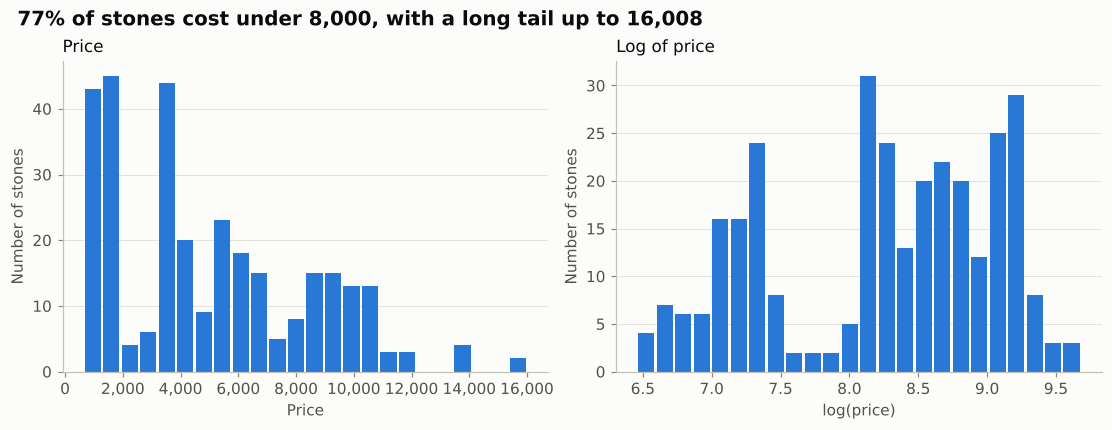

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")

axes[0].hist(df["price"], bins=24, color=BLUE, rwidth=0.88)
axes[0].set(title="Price", xlabel="Price", ylabel="Number of stones")
axes[0].xaxis.set_major_formatter(thousands)

axes[1].hist(df["log_price"], bins=24, color=BLUE, rwidth=0.88)
axes[1].set(title="Log of price", xlabel="log(price)", ylabel="Number of stones")

for ax in axes:
    ax.grid(axis="x", visible=False)

share_under_8000 = (df["price"] < 8000).mean()
headline(fig, f"{share_under_8000:.0%} of stones cost under 8,000, with a long tail up to {df['price'].max():,.0f}")
plt.show()

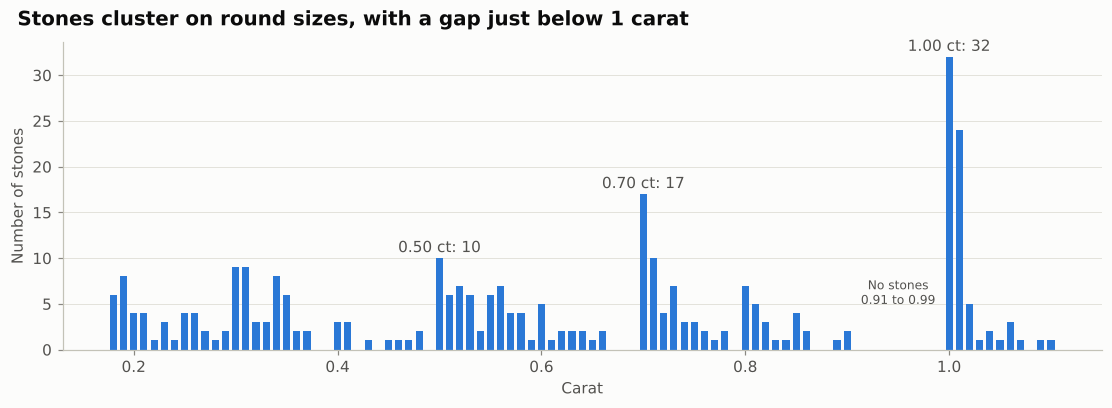

In [7]:
counts = df["carat"].round(2).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
ax.bar(counts.index, counts.values, width=0.007, color=BLUE)
ax.set(xlabel="Carat", ylabel="Number of stones")
ax.grid(axis="x", visible=False)

for size in [0.5, 0.7, 1.0]:
    ax.annotate(f"{size:.2f} ct: {counts[size]}", (size, counts[size]), xytext=(0, 4),
                textcoords="offset points", ha="center", color=INK_2)
ax.annotate("No stones\n0.91 to 0.99", (0.95, 5), ha="center", color=INK_2, fontsize=8)

headline(fig, "Stones cluster on round sizes, with a gap just below 1 carat")
plt.show()

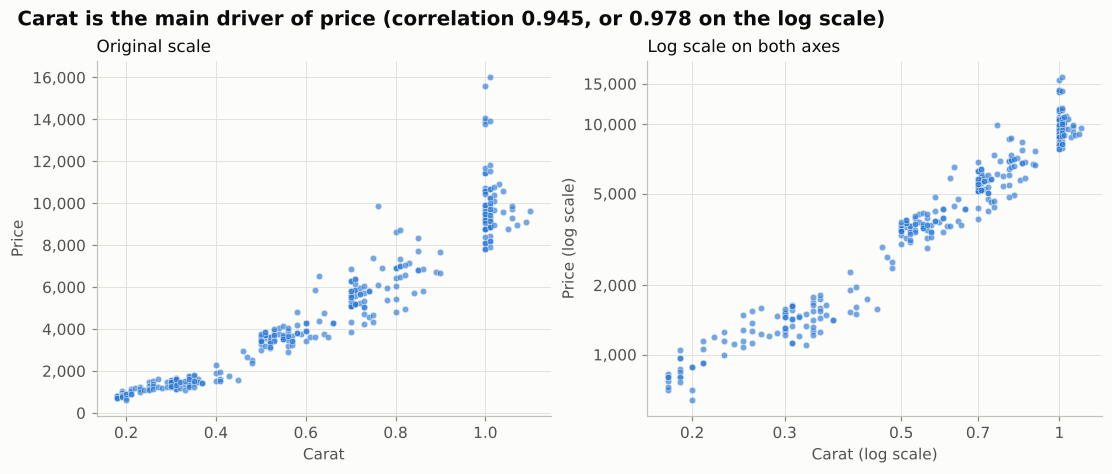

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
point_style = dict(s=18, color=BLUE, alpha=0.65, edgecolor=SURFACE, linewidth=0.4)

axes[0].scatter(df["carat"], df["price"], **point_style)
axes[0].set(title="Original scale", xlabel="Carat", ylabel="Price")
axes[0].yaxis.set_major_formatter(thousands)

axes[1].scatter(df["carat"], df["price"], **point_style)
axes[1].set(title="Log scale on both axes", xlabel="Carat (log scale)", ylabel="Price (log scale)")
log_price_carat_axes(axes[1])

r_raw = df["carat"].corr(df["price"])
r_log = df["log_carat"].corr(df["log_price"])
headline(fig, f"Carat is the main driver of price (correlation {r_raw:.3f}, or {r_log:.3f} on the log scale)")
plt.show()

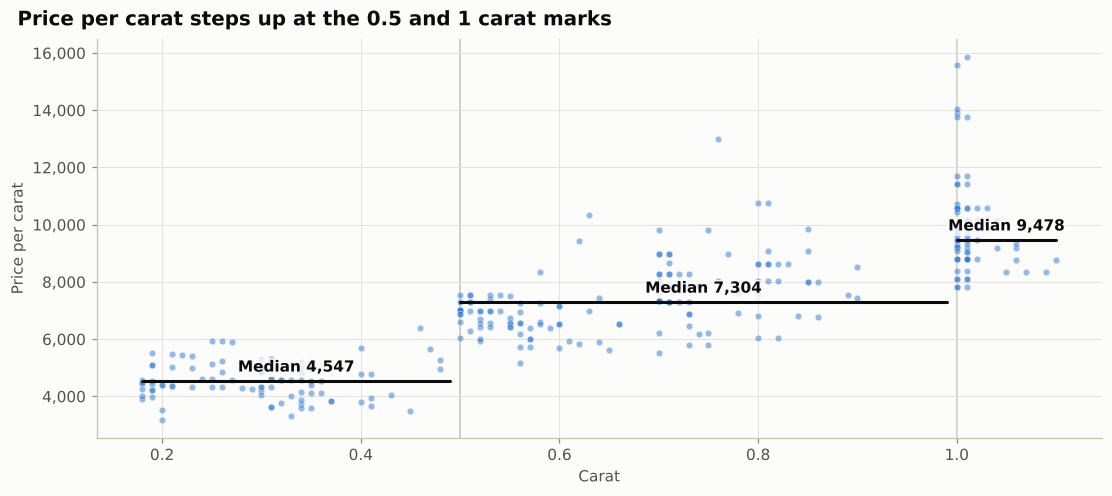

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
ax.scatter(df["carat"], df["price_per_carat"], s=18, color=BLUE, alpha=0.5, edgecolor=SURFACE, linewidth=0.4)

segments = {"Under 0.5 ct": (df["carat"].min(), 0.49), "0.5 to under 1 ct": (0.5, 0.99), "1 ct and over": (1.0, df["carat"].max())}
band_medians = df.groupby("size_band", observed=True)["price_per_carat"].median()
for band, (start, end) in segments.items():
    ax.plot([start, end], [band_medians[band]] * 2, color=INK, linewidth=2, solid_capstyle="round")
    ax.annotate(f"Median {band_medians[band]:,.0f}", ((start + end) / 2, band_medians[band]), xytext=(0, 6),
                textcoords="offset points", ha="center", color=INK, fontweight="bold",
                bbox=dict(facecolor=SURFACE, edgecolor="none", alpha=0.8, pad=1))

for threshold in [0.5, 1.0]:
    ax.axvline(threshold, color=AXIS, linewidth=1, zorder=0)

ax.set(xlabel="Carat", ylabel="Price per carat")
ax.yaxis.set_major_formatter(thousands)
headline(fig, "Price per carat steps up at the 0.5 and 1 carat marks")
plt.show()

## 5. Why raw comparisons mislead

The next chart compares each grade directly. The top row suggests that IF stones, the highest clarity in the data, are the *cheapest*. The bottom row explains why: **those stones are much smaller**. Certification shows the same pattern.

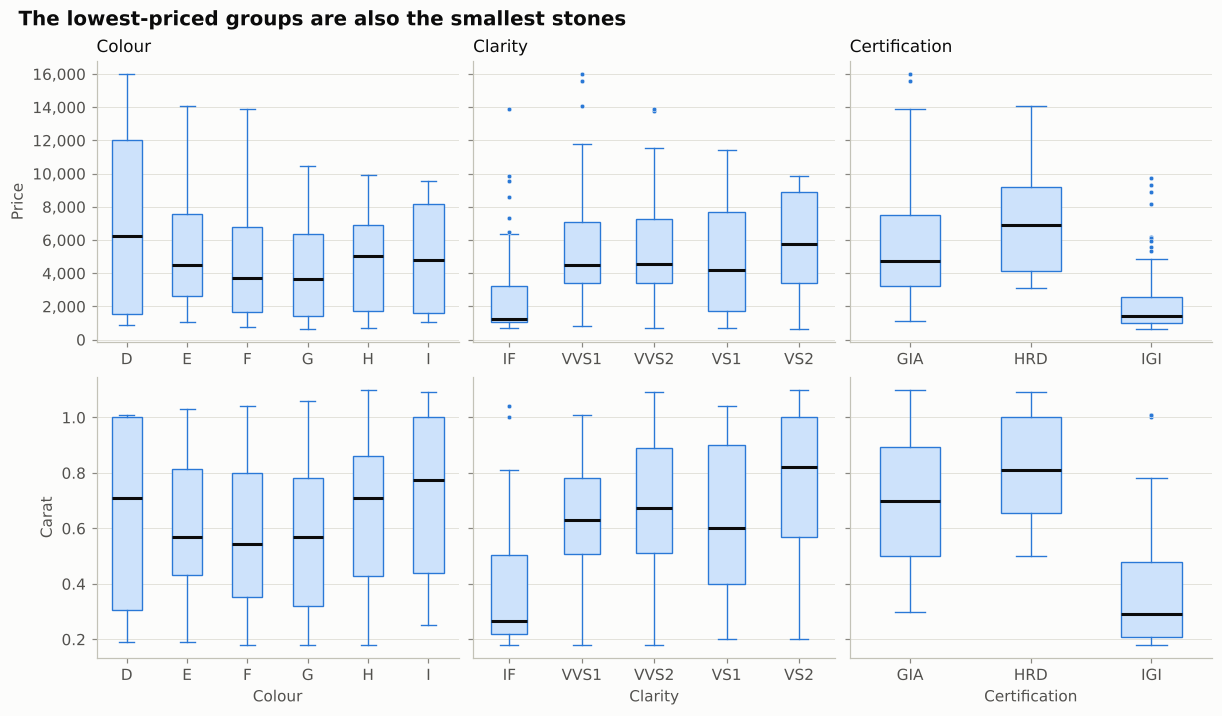

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharey="row", layout="constrained")
groups = [("colour", COLOUR_ORDER), ("clarity", CLARITY_ORDER), ("certification", CERT_ORDER)]


def draw_box(ax, column, levels, value):
    data = [df.loc[df[column] == level, value].to_numpy() for level in levels]
    ax.boxplot(
        data, positions=range(len(levels)), widths=0.5, patch_artist=True,
        boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE, linewidth=0.9),
        medianprops=dict(color=INK, linewidth=2),
        whiskerprops=dict(color=BLUE, linewidth=0.9),
        capprops=dict(color=BLUE, linewidth=0.9),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=BLUE, markeredgecolor=SURFACE, markeredgewidth=0.3),
    )
    ax.set_xticks(range(len(levels)), levels)
    ax.grid(axis="x", visible=False)


for i, (column, levels) in enumerate(groups):
    draw_box(axes[0, i], column, levels, "price")
    draw_box(axes[1, i], column, levels, "carat")
    axes[0, i].set_title(column.capitalize())
    axes[1, i].set_xlabel(column.capitalize())

axes[0, 0].set_ylabel("Price")
axes[0, 0].yaxis.set_major_formatter(thousands)
axes[1, 0].set_ylabel("Carat")
headline(fig, "The lowest-priced groups are also the smallest stones")
plt.show()

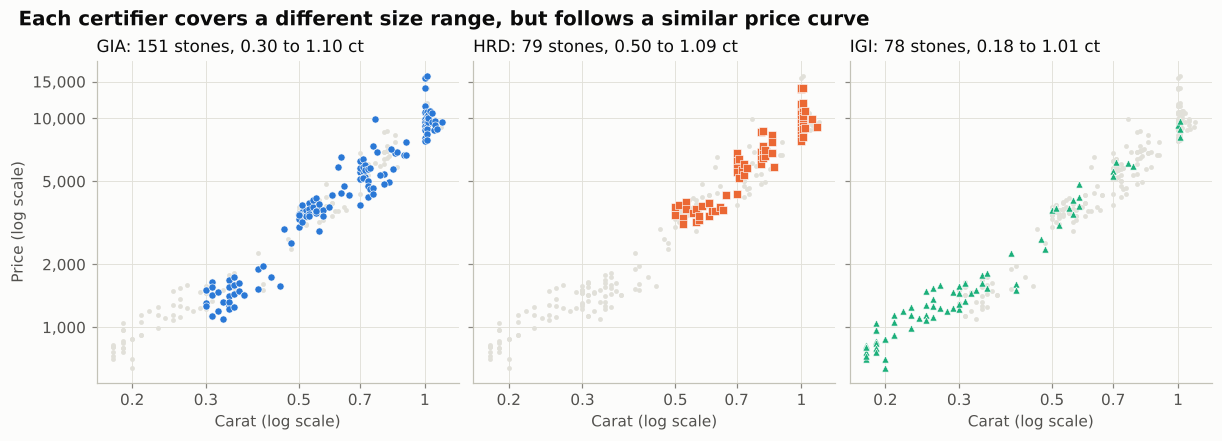

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharex=True, sharey=True, layout="constrained")

for ax, certificate in zip(axes, CERT_ORDER):
    selected = df["certification"] == certificate
    ax.scatter(df.loc[~selected, "carat"], df.loc[~selected, "price"], s=10, color=GRID, linewidth=0)
    ax.scatter(df.loc[selected, "carat"], df.loc[selected, "price"], s=22, color=CERT_COLOURS[certificate],
               marker=CERT_MARKERS[certificate], edgecolor=SURFACE, linewidth=0.4)
    carat_low, carat_high = df.loc[selected, "carat"].min(), df.loc[selected, "carat"].max()
    ax.set_title(f"{certificate}: {selected.sum()} stones, {carat_low:.2f} to {carat_high:.2f} ct")
    ax.set_xlabel("Carat (log scale)")
    log_price_carat_axes(ax)

axes[0].set_ylabel("Price (log scale)")
headline(fig, "Each certifier covers a different size range, but follows a similar price curve")
plt.show()

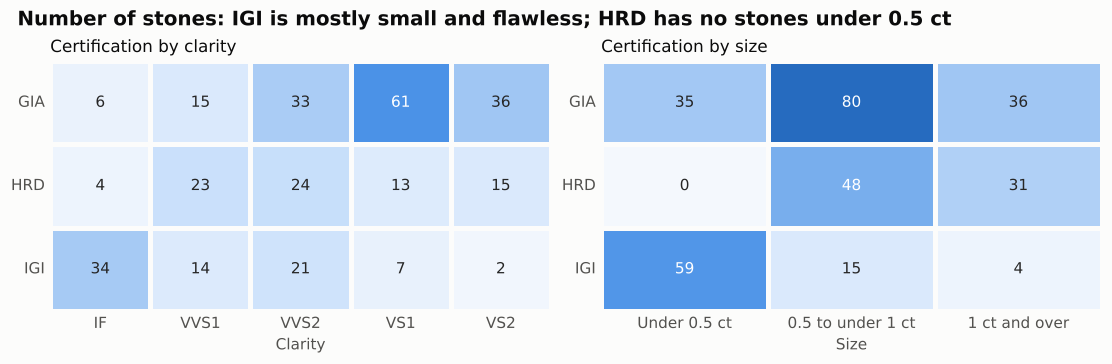

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
tables = [
    (pd.crosstab(df["certification"], df["clarity"]), "Certification by clarity", "Clarity"),
    (pd.crosstab(df["certification"], df["size_band"]), "Certification by size", "Size"),
]
for ax, (table, title, xlabel) in zip(axes, tables):
    sns.heatmap(table, annot=True, fmt="d", cmap=BLUES, vmin=0, vmax=110, cbar=False,
                linewidths=2, linecolor=SURFACE, ax=ax, annot_kws={"fontsize": 10})
    ax.set(title=title, xlabel=xlabel, ylabel="")
    ax.tick_params(length=0, rotation=0)
    ax.grid(False)

headline(fig, "Number of stones: IGI is mostly small and flawless; HRD has no stones under 0.5 ct")
plt.show()

In [13]:
kruskal_rows = []
for column, levels in groups:
    samples = [df.loc[df[column] == level, "price"] for level in levels]
    statistic, p_value = stats.kruskal(*samples)
    kruskal_rows.append({"grade": column, "H statistic": statistic, "p-value": f"{p_value:.2e}", "p-value_value": p_value})

pd.DataFrame(kruskal_rows).drop(columns="p-value_value").set_index("grade")

,H statistic,p-value
grade,,
colour,5.23,3.88e-01
clarity,37.52,1.41e-07
certification,101.85,7.65e-23


These Kruskal-Wallis tests check whether raw prices differ across each grade's groups. Clarity and certification show strong differences, while **colour shows no clear difference at all** (p = 0.39).

None of these results can be taken at face value, because the groups also differ in carat. A regression is needed to compare stones of the same size.

## 6. Modelling price

Price is modelled on the log scale because the size effect is multiplicative. The models build up in four steps, each tested with repeated 5-fold cross-validation so that it is scored on stones it did not see during fitting.

The **typical prediction error** below is the mean absolute percentage error on those unseen stones.

In [14]:
COLOUR_TERM = "C(colour, Treatment('I'))"
CLARITY_TERM = "C(clarity, Treatment('VS2'))"
CERT_TERM = "C(certification, Treatment('GIA'))"
GRADES = f"{COLOUR_TERM} + {CLARITY_TERM}"

FORMULAS = {
    "A. Carat only": "log_price ~ log_carat",
    "B. + colour and clarity": f"log_price ~ log_carat + {GRADES}",
    "C. + certification": f"log_price ~ log_carat + {GRADES} + {CERT_TERM}",
    "D. + size steps at 0.5 and 1 ct": f"log_price ~ 0 + C(size_band) + C(size_band):log_carat + {GRADES} + {CERT_TERM}",
}


def cross_validate(formula, data):
    splitter = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)
    errors = []
    for train_index, test_index in splitter.split(data):
        fold_model = smf.ols(formula, data.iloc[train_index]).fit()
        test = data.iloc[test_index]
        predicted = np.exp(fold_model.predict(test))
        errors.append(np.mean(np.abs(predicted / test["price"] - 1)))
    return 100 * np.mean(errors)


comparison = pd.DataFrame([
    {
        "model": name,
        "adjusted R²": smf.ols(formula, df).fit().rsquared_adj,
        "AIC": smf.ols(formula, df).fit().aic,
        "typical prediction error (%)": cross_validate(formula, df),
    }
    for name, formula in FORMULAS.items()
]).set_index("model")

pd.options.display.float_format = lambda v: f"{v:,.3f}"
display(comparison)
pd.options.display.float_format = lambda v: f"{v:,.2f}"

,adjusted R²,AIC,typical prediction error (%)
model,,,
A. Carat only,0.957,-221.400,12.947
B. + colour and clarity,0.991,-696.335,5.978
C. + certification,0.991,-701.170,5.963
D. + size steps at 0.5 and 1 ct,0.997,-996.730,3.956


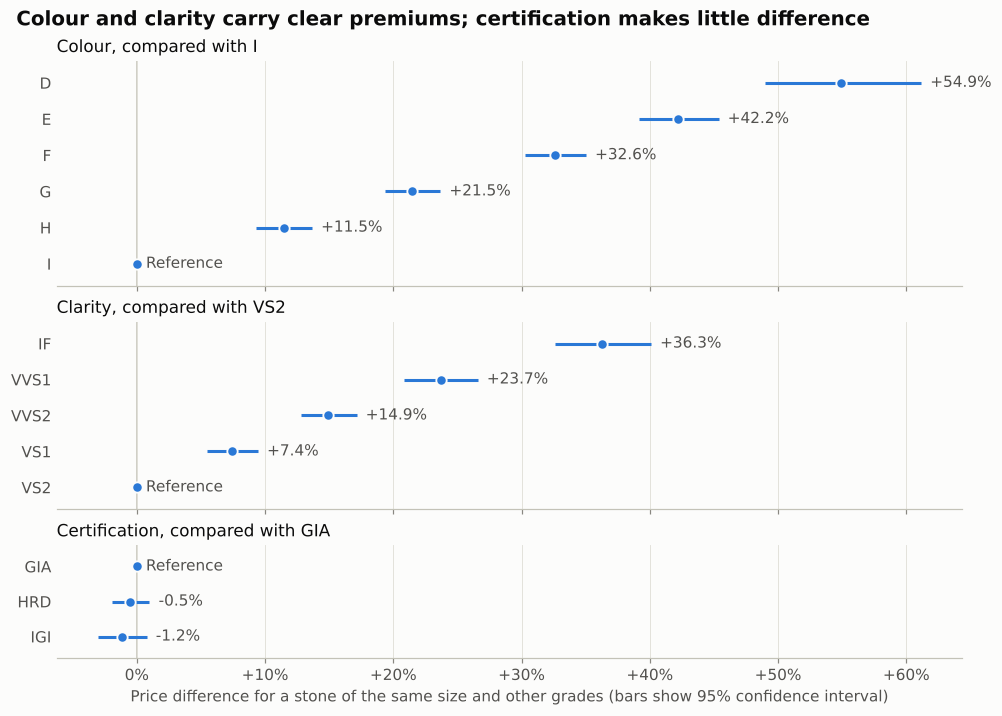

In [15]:
FINAL_FORMULA = FORMULAS["D. + size steps at 0.5 and 1 ct"]

# Robust (HC3) standard errors are used for inference because residual spread is not constant
final_ols = smf.ols(FINAL_FORMULA, df).fit()
final = final_ols.get_robustcov_results(cov_type="HC3")
final_params = pd.Series(final.params, index=final_ols.params.index)
final_ci = pd.DataFrame(final.conf_int(), index=final_ols.params.index, columns=["low", "high"])
final_p = pd.Series(final.pvalues, index=final_ols.params.index)


def premium_table(term, levels, reference):
    rows = []
    for level in levels:
        if level == reference:
            rows.append({"level": level, "premium": 0.0, "low": 0.0, "high": 0.0, "p": np.nan})
            continue
        name = f"{term}[T.{level}]"
        rows.append({
            "level": level,
            "premium": 100 * (np.exp(final_params[name]) - 1),
            "low": 100 * (np.exp(final_ci.loc[name, "low"]) - 1),
            "high": 100 * (np.exp(final_ci.loc[name, "high"]) - 1),
            "p": final_p[name],
        })
    return pd.DataFrame(rows).set_index("level")


colour_premium = premium_table(COLOUR_TERM, COLOUR_ORDER, "I")
clarity_premium = premium_table(CLARITY_TERM, CLARITY_ORDER, "VS2")
cert_premium = premium_table(CERT_TERM, CERT_ORDER, "GIA")

fig, axes = plt.subplots(3, 1, figsize=(9, 6.4), sharex=True, layout="constrained",
                         gridspec_kw={"height_ratios": [6, 5, 3]})
panels = [
    (axes[0], colour_premium, "Colour, compared with I"),
    (axes[1], clarity_premium, "Clarity, compared with VS2"),
    (axes[2], cert_premium, "Certification, compared with GIA"),
]
for ax, table, title in panels:
    y = np.arange(len(table))[::-1]
    ax.hlines(y, table["low"], table["high"], color=BLUE, linewidth=2)
    ax.scatter(table["premium"], y, s=46, color=BLUE, edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.axvline(0, color=AXIS, linewidth=1, zorder=0)
    ax.set_yticks(y, table.index)
    ax.set_ylim(-0.6, len(table) - 0.4)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    for position, (_, row) in zip(y, table.iterrows()):
        label = f"{row['premium']:+.1f}%" if row["premium"] != 0 else "Reference"
        ax.annotate(label, (row["high"], position), xytext=(6, 0),
                    textcoords="offset points", va="center", color=INK_2)

axes[2].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%" if v else "0%"))
axes[2].set_xlabel("Price difference for a stone of the same size and other grades (bars show 95% confidence interval)")
headline(fig, "Colour and clarity carry clear premiums; certification makes little difference")
plt.show()

In [16]:
slopes = pd.DataFrame([
    {
        "size band": band,
        "stones": int((df["size_band"] == band).sum()),
        "carat range": f"{df.loc[df['size_band'] == band, 'carat'].min():.2f} to {df.loc[df['size_band'] == band, 'carat'].max():.2f}",
        "price rise per 1% more carat (%)": final_params[f"C(size_band)[{band}]:log_carat"],
        "95% CI low": final_ci.loc[f"C(size_band)[{band}]:log_carat", "low"],
        "95% CI high": final_ci.loc[f"C(size_band)[{band}]:log_carat", "high"],
    }
    for band in BAND_ORDER
]).set_index("size band")
slopes

,stones,carat range,price rise per 1% more carat (%),95% CI low,95% CI high
size band,,,,,
Under 0.5 ct,94,0.18 to 0.48,1.25,1.21,1.29
0.5 to under 1 ct,143,0.50 to 0.90,1.64,1.60,1.69
1 ct and over,71,1.00 to 1.10,1.07,0.46,1.69


### Raw differences compared with like-for-like premiums

This table shows how much the size adjustment changes the picture. *Raw* compares median prices with the reference grade, while *adjusted* comes from the model above.

In [17]:
def raw_vs_adjusted(column, levels, reference, premium):
    medians = df.groupby(column, observed=True)["price"].median()
    carats = df.groupby(column, observed=True)["carat"].median()
    return pd.DataFrame({
        "grade": column,
        "level": levels,
        "median carat": [carats[level] for level in levels],
        "raw difference (%)": [100 * (medians[level] / medians[reference] - 1) for level in levels],
        "adjusted premium (%)": [premium.loc[level, "premium"] for level in levels],
    }).set_index(["grade", "level"])


raw_adjusted = pd.concat([
    raw_vs_adjusted("colour", COLOUR_ORDER, "I", colour_premium),
    raw_vs_adjusted("clarity", CLARITY_ORDER, "VS2", clarity_premium),
    raw_vs_adjusted("certification", CERT_ORDER, "GIA", cert_premium),
])
raw_adjusted

median carat  raw difference (%)  adjusted premium (%)
grade         level                                                        
colour        D              0.71               31.10                 54.94
              E              0.57               -6.17                 42.21
              F              0.55              -22.29                 32.63
              G              0.57              -23.61                 21.49
              H              0.71                5.24                 11.45
              I              0.78                0.00                  0.00
clarity       IF             0.27              -77.95                 36.30
              VVS1           0.63              -21.34                 23.68
              VVS2           0.68              -20.98                 14.94
              VS1            0.60              -26.44                  7.45
              VS2            0.82                0.00                  0.00
certification GIA            0.70                0.00                  0.00
              HRD            0.81               45.09                 -0.50
              IGI            0.29              -70.33                 -1.16

### Testing the grades and certification

The first table below tests whether each group of grades matters overall. The second refits the model in three ways to see whether the certification result is stable. The narrow range is useful because it compares certifiers only where all three have stones.

In [18]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    joint_tests = smf.ols(FINAL_FORMULA, df).fit(cov_type="HC3").wald_test_terms(scalar=True).table

joint_tests = joint_tests.loc[[COLOUR_TERM, CLARITY_TERM, CERT_TERM], ["statistic", "pvalue", "df_constraint"]]
joint_tests.index = ["Colour", "Clarity", "Certification"]
certification_p = joint_tests.loc["Certification", "pvalue"]
joint_tests["pvalue"] = joint_tests["pvalue"].map(lambda p: "below 1e-100" if p < 1e-100 else f"{p:.3f}")
display(joint_tests.rename(columns={"statistic": "chi-squared", "pvalue": "p-value", "df_constraint": "df"}))


def cert_sensitivity(label, data):
    data = data.copy()
    data["size_band"] = data["size_band"].cat.remove_unused_categories()
    fitted = smf.ols(FINAL_FORMULA, data).fit(cov_type="HC3")
    row = {"fit": label, "stones": len(data)}
    for certificate in ["HRD", "IGI"]:
        name = f"{CERT_TERM}[T.{certificate}]"
        low, high = fitted.conf_int().loc[name]
        row[f"{certificate} vs GIA (%)"] = 100 * (np.exp(fitted.params[name]) - 1)
        row[f"{certificate} 95% CI"] = f"{100 * (np.exp(low) - 1):+.1f} to {100 * (np.exp(high) - 1):+.1f}"
    return row


sensitivity = pd.DataFrame([
    cert_sensitivity("All stones", df),
    cert_sensitivity("Repeat rows removed", df[~duplicates]),
    cert_sensitivity("0.50 to 1.01 ct only", df[df["carat"].between(0.5, 1.01)]),
]).set_index("fit")
sensitivity

,chi-squared,p-value,df
Colour,"1,472.46",below 1e-100,5
Clarity,583.26,below 1e-100,4
Certification,1.55,0.461,2


,stones,HRD vs GIA (%),HRD 95% CI,IGI vs GIA (%),IGI 95% CI
fit,,,,,
All stones,308,-0.50,-2.0 to +1.0,-1.16,-3.0 to +0.8
Repeat rows removed,300,-0.29,-1.8 to +1.2,-1.07,-2.9 to +0.8
0.50 to 1.01 ct only,199,-0.66,-2.2 to +0.9,-2.63,-4.9 to -0.3


## 7. Checking the model

A good model should show three things: predictions close to the actual prices, no pattern in the residuals, and residuals close to a normal distribution.

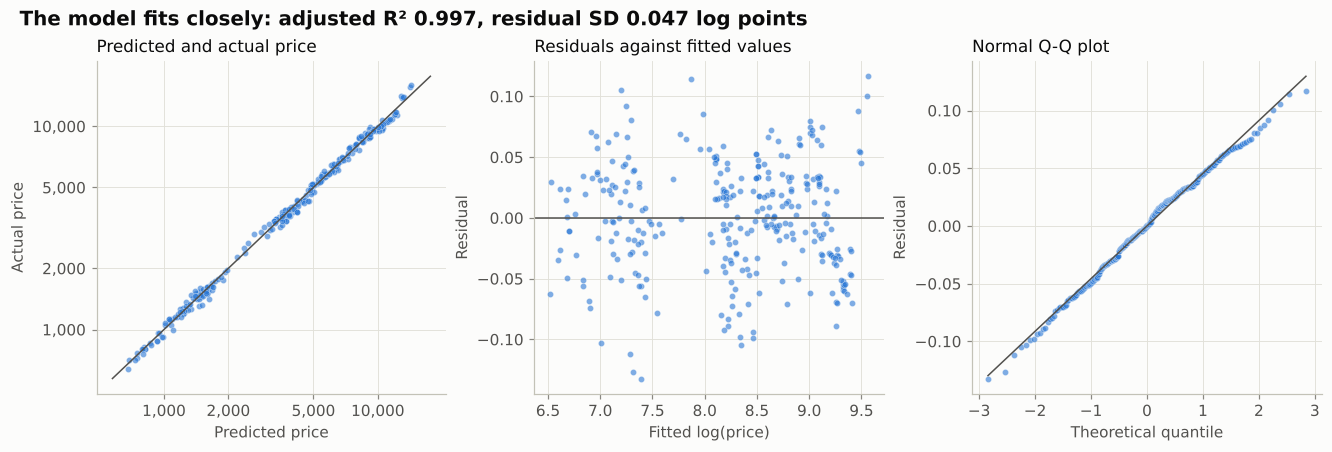

,result
Shapiro-Wilk p-value (normal residuals),0.3566
Breusch-Pagan p-value (constant spread),0.0001
Stones with |studentised residual| > 3,0
Largest |studentised residual|,2.94


In [19]:
fitted_price = np.exp(final_ols.fittedvalues)
residuals = final_ols.resid
student = final_ols.get_influence().resid_studentized_external

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")

axes[0].scatter(fitted_price, df["price"], s=16, color=BLUE, alpha=0.6, edgecolor=SURFACE, linewidth=0.3)
limits = [df["price"].min() * 0.9, df["price"].max() * 1.1]
axes[0].plot(limits, limits, color=INK_2, linewidth=1)
axes[0].set(title="Predicted and actual price", xlabel="Predicted price", ylabel="Actual price", xscale="log", yscale="log")
for axis in [axes[0].xaxis, axes[0].yaxis]:
    axis.set_major_formatter(thousands)
    axis.set_minor_formatter(NullFormatter())
axes[0].set_xticks([1000, 2000, 5000, 10000])
axes[0].set_yticks([1000, 2000, 5000, 10000])
axes[0].tick_params(which="minor", length=0)

axes[1].scatter(final_ols.fittedvalues, residuals, s=16, color=BLUE, alpha=0.6, edgecolor=SURFACE, linewidth=0.3)
axes[1].axhline(0, color=INK_2, linewidth=1)
axes[1].set(title="Residuals against fitted values", xlabel="Fitted log(price)", ylabel="Residual")

(theoretical, ordered), (slope, intercept, _) = stats.probplot(residuals)
axes[2].scatter(theoretical, ordered, s=16, color=BLUE, alpha=0.6, edgecolor=SURFACE, linewidth=0.3)
axes[2].plot(theoretical, slope * theoretical + intercept, color=INK_2, linewidth=1)
axes[2].set(title="Normal Q-Q plot", xlabel="Theoretical quantile", ylabel="Residual")

headline(fig, f"The model fits closely: adjusted R² {final_ols.rsquared_adj:.3f}, residual SD {np.sqrt(final_ols.scale):.3f} log points")
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
# The test needs an explicit constant, which replaces the first size-band column
bp_exog = np.column_stack([np.ones(len(df)), final_ols.model.exog[:, 1:]])
bp_stat, bp_p, _, _ = het_breuschpagan(residuals, bp_exog)
pd.DataFrame({
    "result": [f"{shapiro_p:.4f}", f"{bp_p:.4f}", int((np.abs(student) > 3).sum()), f"{np.abs(student).max():.2f}"],
}, index=["Shapiro-Wilk p-value (normal residuals)", "Breusch-Pagan p-value (constant spread)",
          "Stones with |studentised residual| > 3", "Largest |studentised residual|"])

In [20]:
worst = df.assign(
    predicted=fitted_price.round(0),
    error_pct=100 * (fitted_price / df["price"] - 1),
    studentised=student,
).loc[lambda d: d["studentised"].abs().sort_values(ascending=False).index[:8],
      ["carat", "colour", "clarity", "certification", "price", "predicted", "error_pct", "studentised"]]
worst

,carat,colour,clarity,certification,price,predicted,error_pct,studentised
26,0.37,F,VS2,GIA,1420,"1,621.00",14.14,-2.94
12,0.33,E,VS2,GIA,1327,"1,506.00",13.49,-2.82
130,1.01,D,VVS1,GIA,16008,"14,247.00",-11.00,2.66
33,0.46,E,VVS2,GIA,2942,"2,623.00",-10.83,2.59
0,0.30,D,VS2,GIA,1302,"1,456.00",11.85,-2.55
241,0.58,H,IF,HRD,3792,"4,210.00",11.02,-2.33
178,0.25,F,IF,IGI,1485,"1,337.00",-9.99,2.31
115,1.00,D,VVS1,GIA,15582,"14,095.00",-9.54,2.29


## 8. Estimating the price of a new stone

`estimate_price` returns the model's estimate and a 95% prediction interval. It rejects sizes outside the range of the data and warns inside the 0.91 to 0.99 carat gap, where the model has no stones to learn from.

In [21]:
def estimate_price(carat, colour, clarity, certification="GIA", level=0.95):
    if not df["carat"].min() <= carat <= df["carat"].max():
        raise ValueError(f"Carat must be between {df['carat'].min()} and {df['carat'].max()}.")
    if 0.90 < carat < 1.00:
        warnings.warn("No stones from 0.91 to 0.99 carat exist in the data, so treat this estimate with caution.")

    stone = pd.DataFrame({
        "log_carat": [np.log(carat)],
        "size_band": pd.Categorical(pd.cut([carat], [0, 0.5, 1, np.inf], right=False, labels=BAND_ORDER), BAND_ORDER, ordered=True),
        "colour": pd.Categorical([colour], COLOUR_ORDER, ordered=True),
        "clarity": pd.Categorical([clarity], CLARITY_ORDER, ordered=True),
        "certification": pd.Categorical([certification], CERT_ORDER),
    })
    if stone[["colour", "clarity", "certification"]].isna().any(axis=None):
        raise ValueError("Unknown colour, clarity or certification grade.")

    prediction = final_ols.get_prediction(stone).summary_frame(alpha=1 - level).iloc[0]
    return pd.Series({
        "estimate": np.exp(prediction["mean"]),
        "interval_low": np.exp(prediction["obs_ci_lower"]),
        "interval_high": np.exp(prediction["obs_ci_upper"]),
    }).round(0)


examples = [
    (0.30, "F", "VS1", "GIA"),
    (0.50, "G", "VVS2", "GIA"),
    (0.70, "H", "VS2", "HRD"),
    (1.00, "D", "VVS1", "GIA"),
    (1.00, "I", "VS2", "IGI"),
]
pd.DataFrame(
    [estimate_price(*example) for example in examples],
    index=pd.MultiIndex.from_tuples(examples, names=["carat", "colour", "clarity", "certification"]),
)

estimate  interval_low  interval_high
carat colour clarity certification                                       
0.30  F      VS1     GIA            1,339.00      1,220.00       1,471.00
0.50  G      VVS2    GIA            3,048.00      2,774.00       3,348.00
0.70  H      VS2     HRD            4,207.00      3,830.00       4,622.00
1.00  D      VVS1    GIA           14,095.00     12,797.00      15,525.00
      I      VS2     IGI            7,270.00      6,604.00       8,003.00

## 9. Key findings

In [22]:
reference = dict(colour="G", clarity="VS1", certification="GIA")
step_half = estimate_price(0.50, **reference)["estimate"] / estimate_price(0.48, **reference)["estimate"] - 1
step_one = estimate_price(1.00, **reference)["estimate"] / estimate_price(0.90, **reference)["estimate"] - 1
size_gain_half = 0.5 / 0.48 - 1
size_gain_one = 1.0 / 0.90 - 1

if_row = raw_adjusted.loc[("clarity", "IF")]
igi = cert_premium.loc["IGI"]
hrd = cert_premium.loc["HRD"]
narrow = sensitivity.loc["0.50 to 1.01 ct only"]

display(Markdown(f"""
1. **Carat matters most.** Carat alone explains {100 * comparison.loc['A. Carat only', 'adjusted R²']:.1f}% of the variation in log price. Price also rises faster than size: within the largest group of stones, 0.5 to under 1 carat, 1% more carat adds about {slopes.loc['0.5 to under 1 ct', 'price rise per 1% more carat (%)']:.2f}% to the price.
2. **Price jumps at round sizes.** For a G, VS1, GIA stone, moving from 0.48 to 0.50 carat is {100 * size_gain_half:.0f}% more diamond but {100 * step_half:.0f}% more price. Moving from 0.90 to 1.00 carat is {100 * size_gain_one:.0f}% more diamond but {100 * step_one:.0f}% more price. The second figure spans the gap in the data, so the exact point of the jump cannot be pinned down.
3. **Colour has a clear ladder that raw prices hide.** Raw prices show no clear difference across colours (p = {kruskal_rows[0]['p-value_value']:.2f}). With other features held constant, D stones cost {colour_premium.loc['D', 'premium']:.0f}% more than I stones, and the premium falls at every step down the scale.
4. **Clarity is hidden by size in raw comparisons.** IF stones have a raw median price {abs(if_row['raw difference (%)']):.0f}% *below* VS2, but their median size is only {if_row['median carat']:.2f} carat. Compared like for like, they carry a {if_row['adjusted premium (%)']:.0f}% *premium*.
5. **Certification has little effect on price.** The large raw gaps mostly reflect stone size. In the full model, HRD is {hrd['premium']:+.1f}% and IGI is {igi['premium']:+.1f}% against GIA, and the joint test finds no significant difference (p = {certification_p:.2f}). Among the {narrow['stones']:.0f} stones from 0.50 to 1.01 carat, IGI is {narrow['IGI vs GIA (%)']:+.1f}% (95% CI {narrow['IGI 95% CI']}), so any real gap looks like a few percent at most.
6. **The final model predicts well.** Its typical error on unseen stones is {comparison.loc['D. + size steps at 0.5 and 1 ct', 'typical prediction error (%)']:.1f}%, compared with {comparison.loc['A. Carat only', 'typical prediction error (%)']:.1f}% using carat alone.

**Limits of this analysis**
- These are observed prices from one dataset with no date or source details, so the results show association rather than cause.
- Cut, which also affects price, is not in the data.
- The size steps were chosen after looking at this data, so the model's error may be slightly optimistic.
- There are few stones above 1.02 carat, and none above 1.10, so the top size range is the least certain.
"""))


1. **Carat matters most.** Carat alone explains 95.7% of the variation in log price. Price also rises faster than size: within the largest group of stones, 0.5 to under 1 carat, 1% more carat adds about 1.64% to the price.
2. **Price jumps at round sizes.** For a G, VS1, GIA stone, moving from 0.48 to 0.50 carat is 4% more diamond but 29% more price. Moving from 0.90 to 1.00 carat is 11% more diamond but 28% more price. The second figure spans the gap in the data, so the exact point of the jump cannot be pinned down.
3. **Colour has a clear ladder that raw prices hide.** Raw prices show no clear difference across colours (p = 0.39). With other features held constant, D stones cost 55% more than I stones, and the premium falls at every step down the scale.
4. **Clarity is hidden by size in raw comparisons.** IF stones have a raw median price 78% *below* VS2, but their median size is only 0.27 carat. Compared like for like, they carry a 36% *premium*.
5. **Certification has little effect on price.** The large raw gaps mostly reflect stone size. In the full model, HRD is -0.5% and IGI is -1.2% against GIA, and the joint test finds no significant difference (p = 0.46). Among the 199 stones from 0.50 to 1.01 carat, IGI is -2.6% (95% CI -4.9 to -0.3), so any real gap looks like a few percent at most.
6. **The final model predicts well.** Its typical error on unseen stones is 4.0%, compared with 12.9% using carat alone.

**Limits of this analysis**
- These are observed prices from one dataset with no date or source details, so the results show association rather than cause.
- Cut, which also affects price, is not in the data.
- The size steps were chosen after looking at this data, so the model's error may be slightly optimistic.
- There are few stones above 1.02 carat, and none above 1.10, so the top size range is the least certain.
